# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
import sklearn








In [2]:
df = pd.DataFrame(pd.read_csv('data/temps.csv'))

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 329 entries, 0 to 328
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     329 non-null    int64  
 1   month    329 non-null    int64  
 2   day      329 non-null    int64  
 3   week     329 non-null    str    
 4   temp_2   329 non-null    int64  
 5   temp_1   329 non-null    int64  
 6   average  329 non-null    float64
 7   actual   329 non-null    int64  
 8   friend   329 non-null    int64  
dtypes: float64(1), int64(7), str(1)
memory usage: 23.3 KB


### 2. Realiza un análisis exploratorio junto con un Feature Engineering

In [4]:
dias = {'Mon': 0, 'Tues': 1, 'Wed': 2, 'Thurs': 3, 'Fri': 4, 'Sat': 5, 'Sun': 6}
df['week'] = df['week'].map(dias) #pasar a int la columna week que es string

In [5]:
df.nunique()

year         1
month       12
day         31
week         7
temp_2      53
temp_1      53
average    238
actual      53
friend      65
dtype: int64

In [6]:
df = df.drop(columns='year')

In [ ]:
df = df[(df['temp_1'] <= 100) & (df['temp_2'] <= 100)]   #  limpiar valores anómalos de temperaturas.

<Figure size 1000x1000 with 0 Axes>

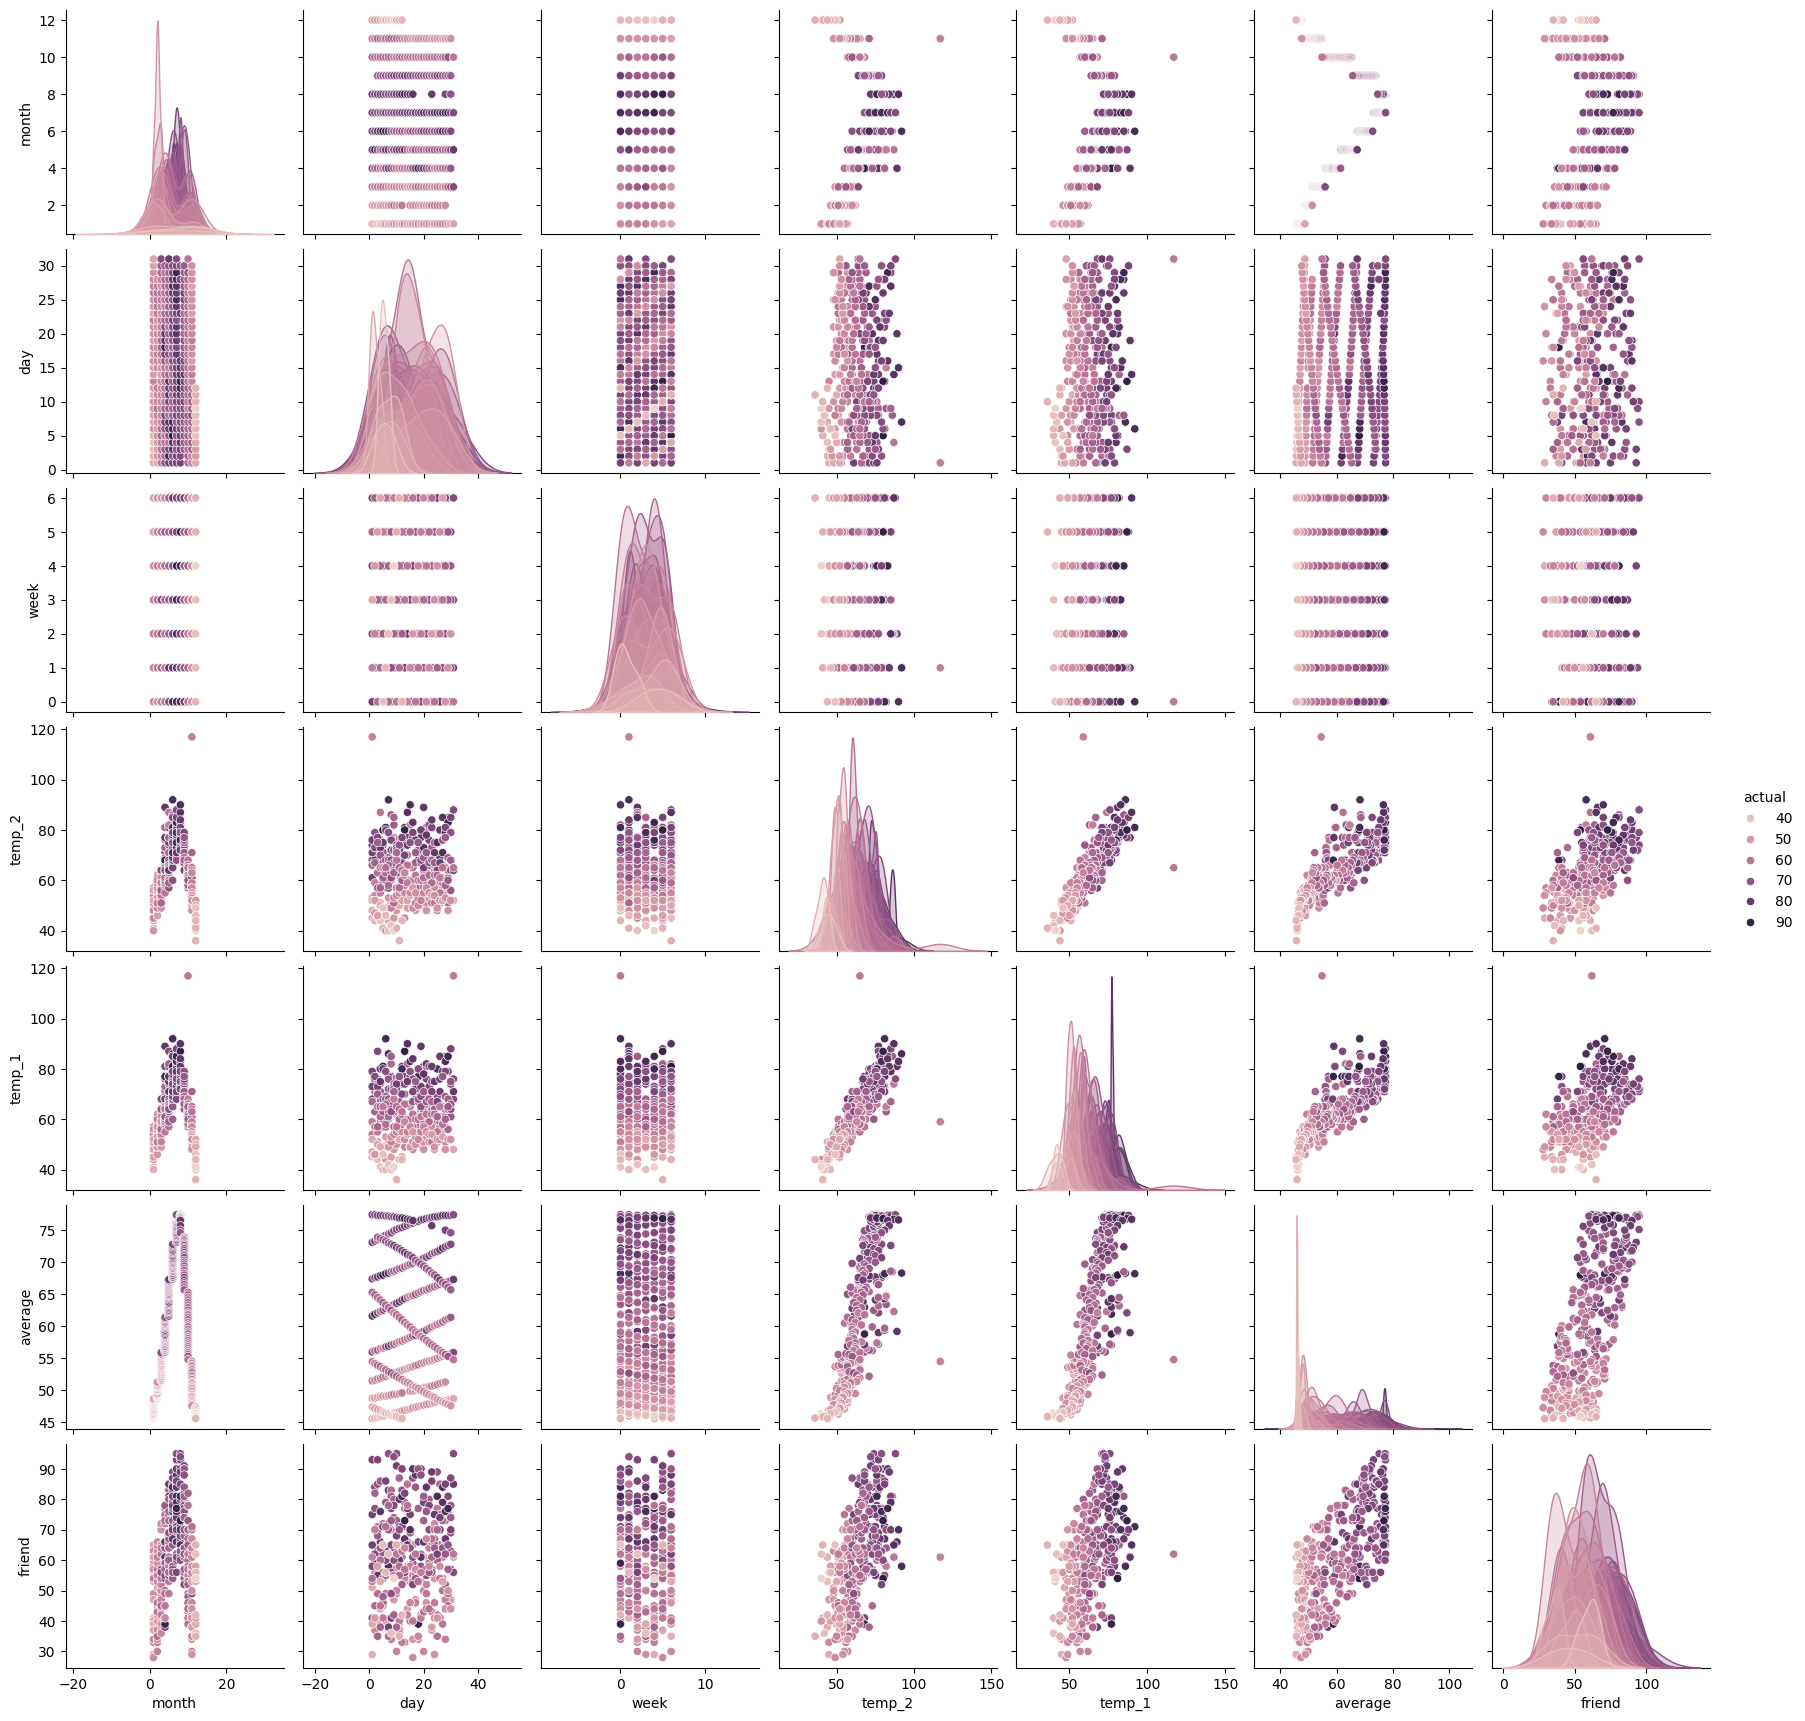

In [7]:


plt.figure(figsize=(10,10))
sns.pairplot(df, hue='actual')


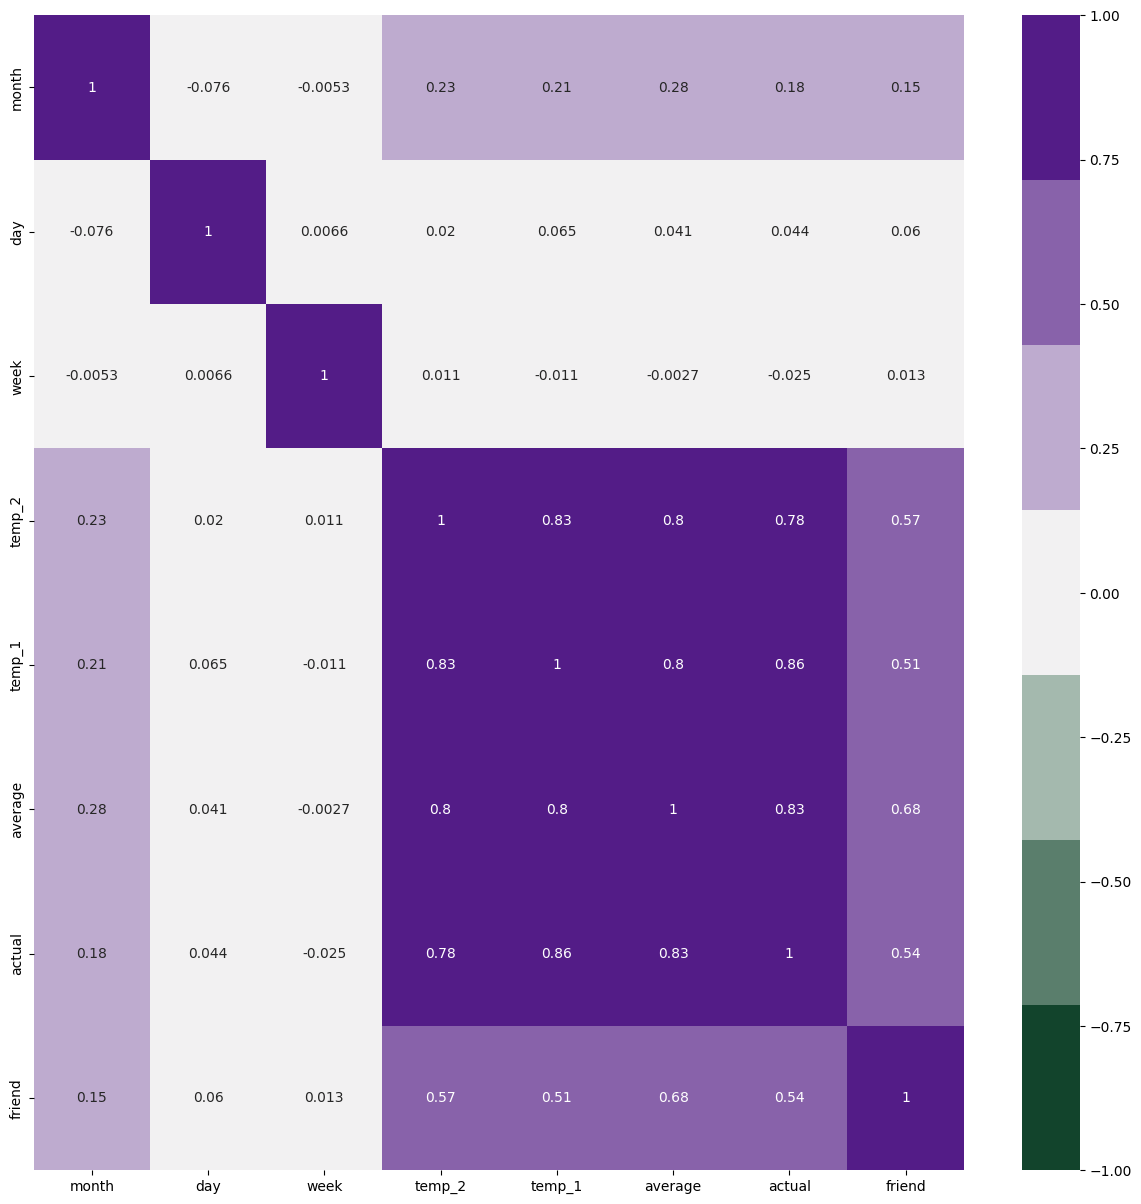

In [8]:
plt.figure(figsize=(15,15))
sns.heatmap(df.corr(),
           vmin=-1,
           vmax=1,
           cmap=sns.diverging_palette(145, 280, s=85, l=25, n=7),
           annot=True);

### 3. Selecciona variables y divide en train y test

In [9]:
Y = df['actual']
X = df.drop(columns='actual')

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=666)




In [10]:
tree_reg = DecisionTreeRegressor(max_depth=2, random_state=666)


### 4. Entrena el modelo


In [11]:
tree_reg.fit(x_train, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",666
,"max_lea

### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [12]:
y_predict = tree_reg.predict(x_test)


In [13]:
y_predict_test = tree_reg.predict(x_train)

In [14]:
from sklearn import metrics
print('MAE:', metrics.mean_absolute_error(y_test, y_predict))
print('MSE:', metrics.mean_squared_error(y_test, y_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_predict)))
print('R2:', metrics.r2_score(y_test, y_predict))

MAE: 5.117575574757022
MSE: 39.95900395185028
RMSE: 6.3213134672985705
R2: 0.7159460859853195


In [15]:
print('MAE:', metrics.mean_absolute_error(y_train, y_predict_test))
print('MSE:', metrics.mean_squared_error(y_train, y_predict_test))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train, y_predict_test)))
print('R2:', metrics.r2_score(y_train, y_predict_test))

MAE: 4.391962583707683
MSE: 28.120750610915902
RMSE: 5.302900207520023
R2: 0.76073806601985


### 6. Representa el árbol de decisión

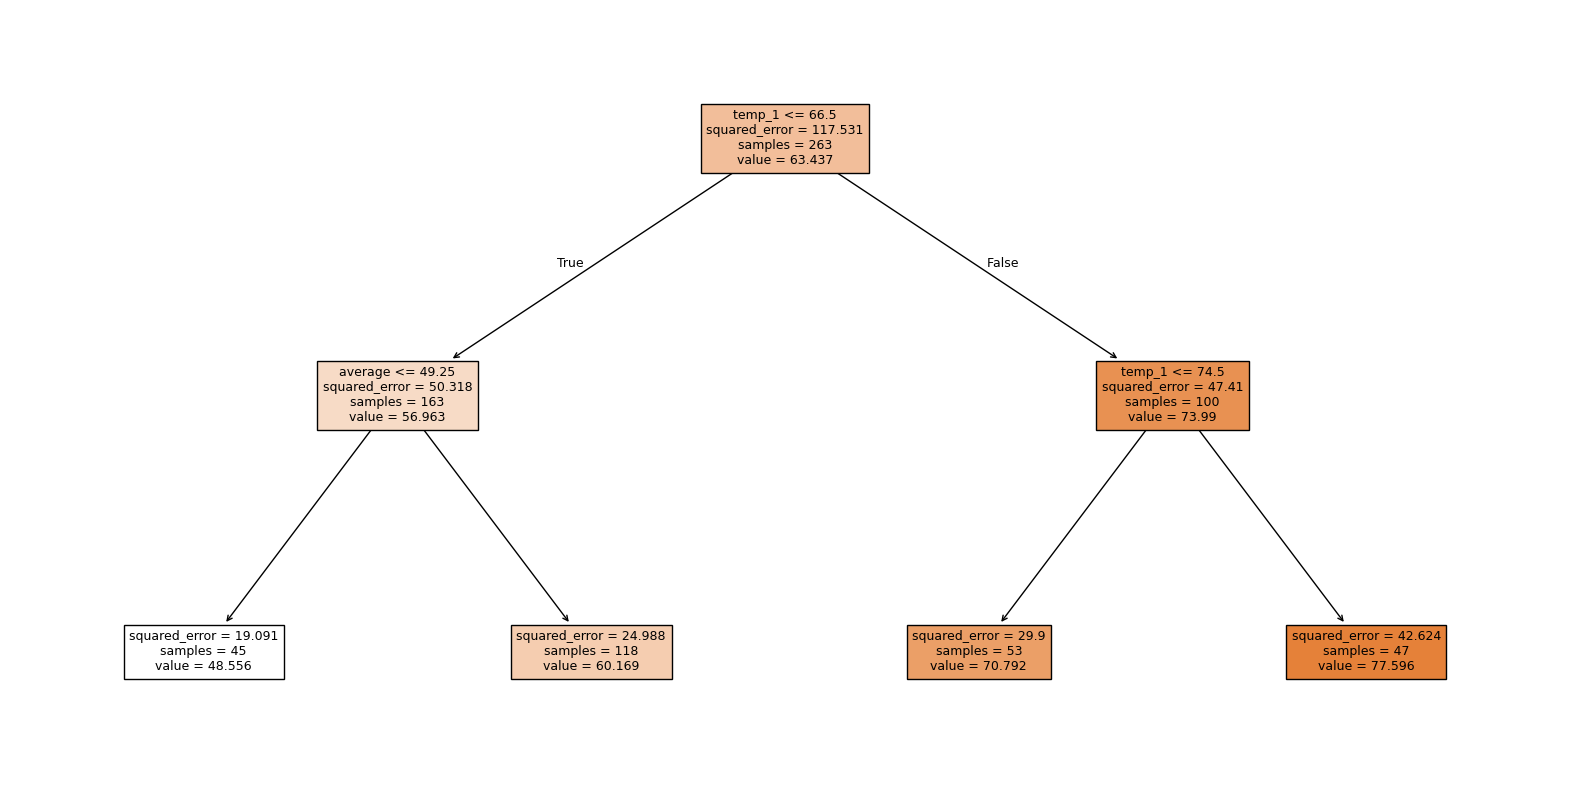

In [16]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(tree_reg,
          feature_names=x_train.columns,
          filled=True,
          max_depth=3,      #DIBUJAR ARBOL DE REGRESION
          fontsize=9)
plt.show()

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [17]:
tree_reg_2 = DecisionTreeRegressor(max_depth=3, random_state=666)


### 8. Vuelve a evaluar tu modelo

In [18]:
tree_reg_2.fit(x_train, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",666
,"max_lea

### 9. Vuelve a representar su árbol

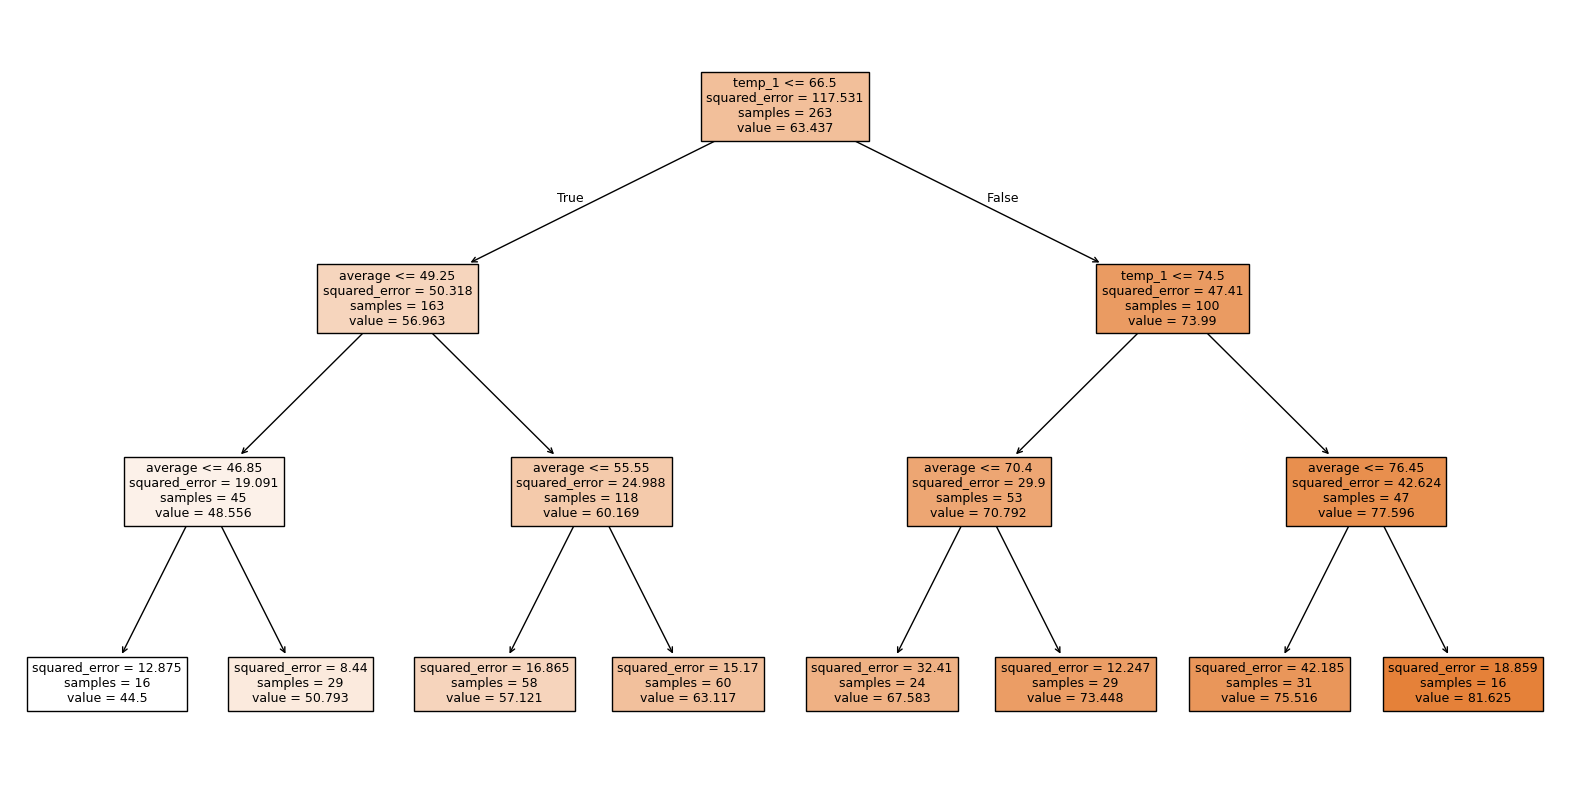

In [19]:

plt.figure(figsize=(20, 10))
plot_tree(tree_reg_2,
          feature_names=x_train.columns,
          filled=True,
          max_depth=3,      #DIBUJAR ARBOL DE REGRESION
          fontsize=9)
plt.show()

In [20]:
y_predict_2 = tree_reg_2.predict(x_test)
x_predict_2 = tree_reg_2.predict(x_train)

In [21]:
print('MAE:', metrics.mean_absolute_error(y_test, y_predict_2))
print('MSE:', metrics.mean_squared_error(y_test, y_predict_2))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_predict_2)))
print('R2:', metrics.r2_score(y_test, y_predict_2))

print('------------------------------------------------------------------')

print('MAE:', metrics.mean_absolute_error(y_train, x_predict_2))
print('MSE:', metrics.mean_squared_error(y_train, x_predict_2))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train, x_predict_2)))
print('R2:', metrics.r2_score(y_train, x_predict_2))

MAE: 4.528382405815665
MSE: 34.08934159567551
RMSE: 5.8386078473961165
R2: 0.7576713644288247
------------------------------------------------------------------
MAE: 3.4686753060364213
MSE: 19.321653266338746
RMSE: 4.395640256701945
R2: 0.835604099187752


In [22]:
importancias = pd.Series(tree_reg_2.feature_importances_, index=x_train.columns)
importancias.sort_values(ascending=False)

temp_1     0.740285
average    0.259715
month      0.000000
week       0.000000
day        0.000000
temp_2     0.000000
friend     0.000000
dtype: float64

MAE: 5.212121212121212
MSE: 48.696969696969695
RMSE: 6.978321409692283
R2: 0.6538310899904696
------------------------------------------------------------------
MAE: 0.0
MSE: 0.0
RMSE: 0.0
R2: 1.0


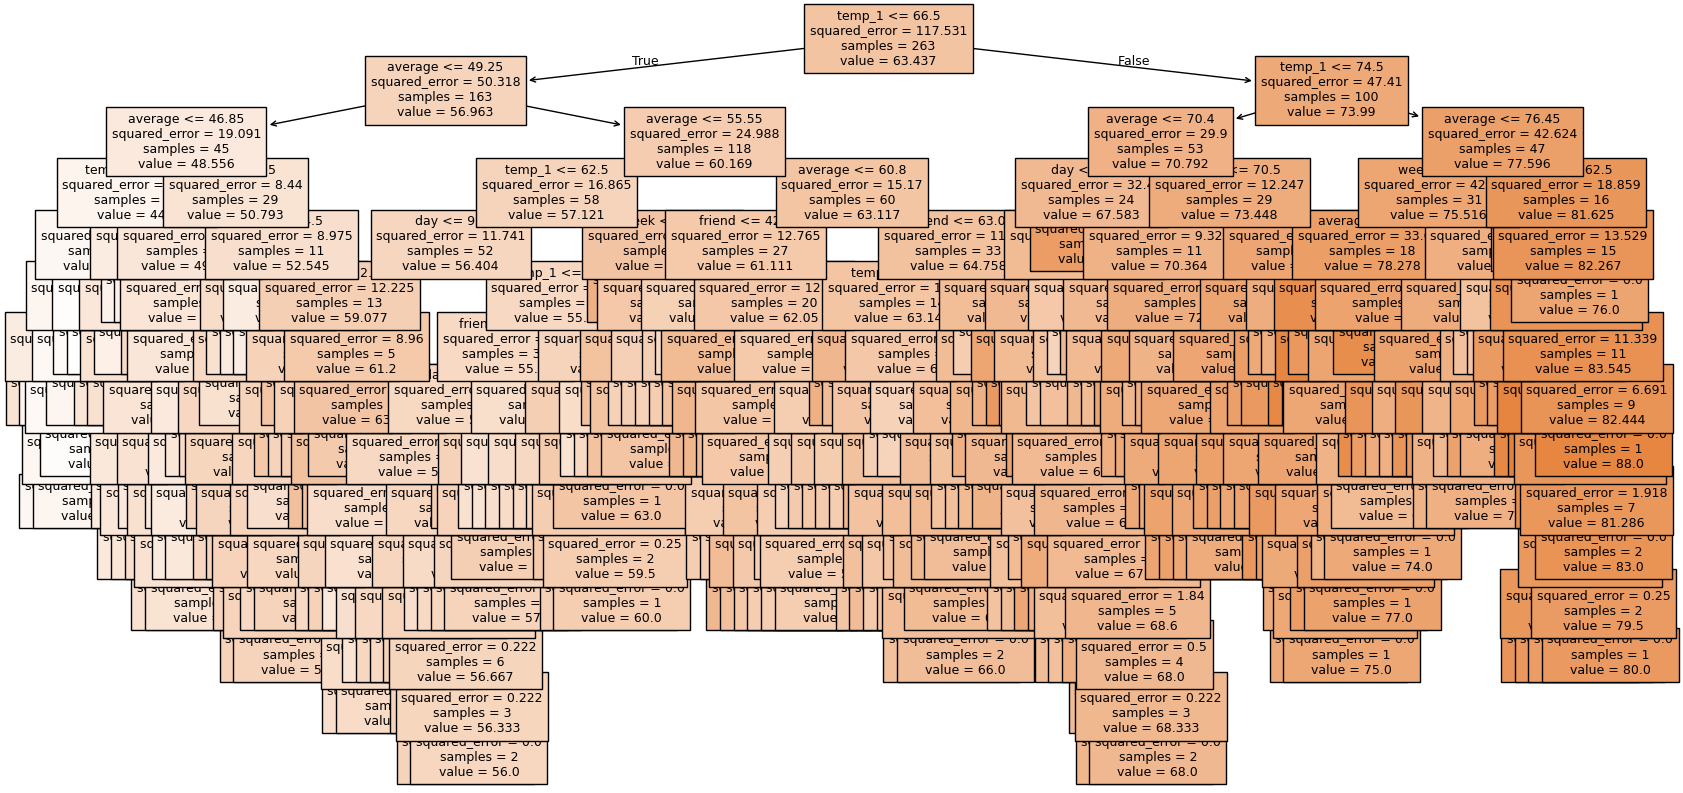

In [23]:
prueba_infinita = DecisionTreeRegressor(random_state=666)
prueba_infinita.fit(x_train, y_train)
y_infinite_predict = prueba_infinita.predict(x_test)
x_infinite_predict = prueba_infinita.predict(x_train)

print('MAE:', metrics.mean_absolute_error(y_test, y_infinite_predict))
print('MSE:', metrics.mean_squared_error(y_test, y_infinite_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_infinite_predict)))
print('R2:', metrics.r2_score(y_test, y_infinite_predict))

print('------------------------------------------------------------------')

print('MAE:', metrics.mean_absolute_error(y_train, x_infinite_predict))
print('MSE:', metrics.mean_squared_error(y_train, x_infinite_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train, x_infinite_predict)))
print('R2:', metrics.r2_score(y_train, x_infinite_predict))

plt.figure(figsize=(20, 10))
plot_tree(prueba_infinita,
          feature_names=x_train.columns,
          filled=True,
                #DIBUJAR ARBOL DE REGRESION
          fontsize=9)
plt.show()

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [24]:
from sklearn.model_selection import GridSearchCV

parametros = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],     # None = sin límite
    'min_samples_leaf': [1, 5, 10, 20],            # mínimo de días que debe tener cada hoja
}

grid = GridSearchCV(
    DecisionTreeRegressor(random_state=666),
    parametros,
    cv=5,                                    # validación cruzada de 5 partes
    scoring='neg_mean_absolute_error',       # elige el que menos se equivoca en grados
)
grid.fit(x_train, y_train)                

print('Mejores parámetros:', grid.best_params_)
print('MAE medio en la validación cruzada:', -grid.best_score_)

mejor_arbol = grid.best_estimator_           # ya viene entrenado con todo el train
y_pred_grid = mejor_arbol.predict(x_test)
print('MAE test:', metrics.mean_absolute_error(y_test, y_pred_grid))
print('R2 test: ', metrics.r2_score(y_test, y_pred_grid))

Mejores parámetros: {'max_depth': 4, 'min_samples_leaf': 10}
MAE medio en la validación cruzada: 3.9680854094250364
MAE test: 4.754247604247603
R2 test:  0.722563957891045


### 11. Obten el `feature_importances` de cada variable en el último modelo

In [34]:
importancias_2 = pd.Series(grid.best_estimator_.feature_importances_, index=x_train.columns) #usar el mejor arbol que encuentra grid search para sacar las importancias
importancias_2.sort_values(ascending=False)

average    0.926416
temp_1     0.073584
month      0.000000
week       0.000000
day        0.000000
temp_2     0.000000
friend     0.000000
dtype: float64

### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.

In [27]:
Y = (df['actual'] > 59).astype(int)
X = df.drop(columns='actual')

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=666)

In [28]:
tree_clf = DecisionTreeClassifier(max_depth=3,
                                  random_state=42)
tree_clf.fit(x_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

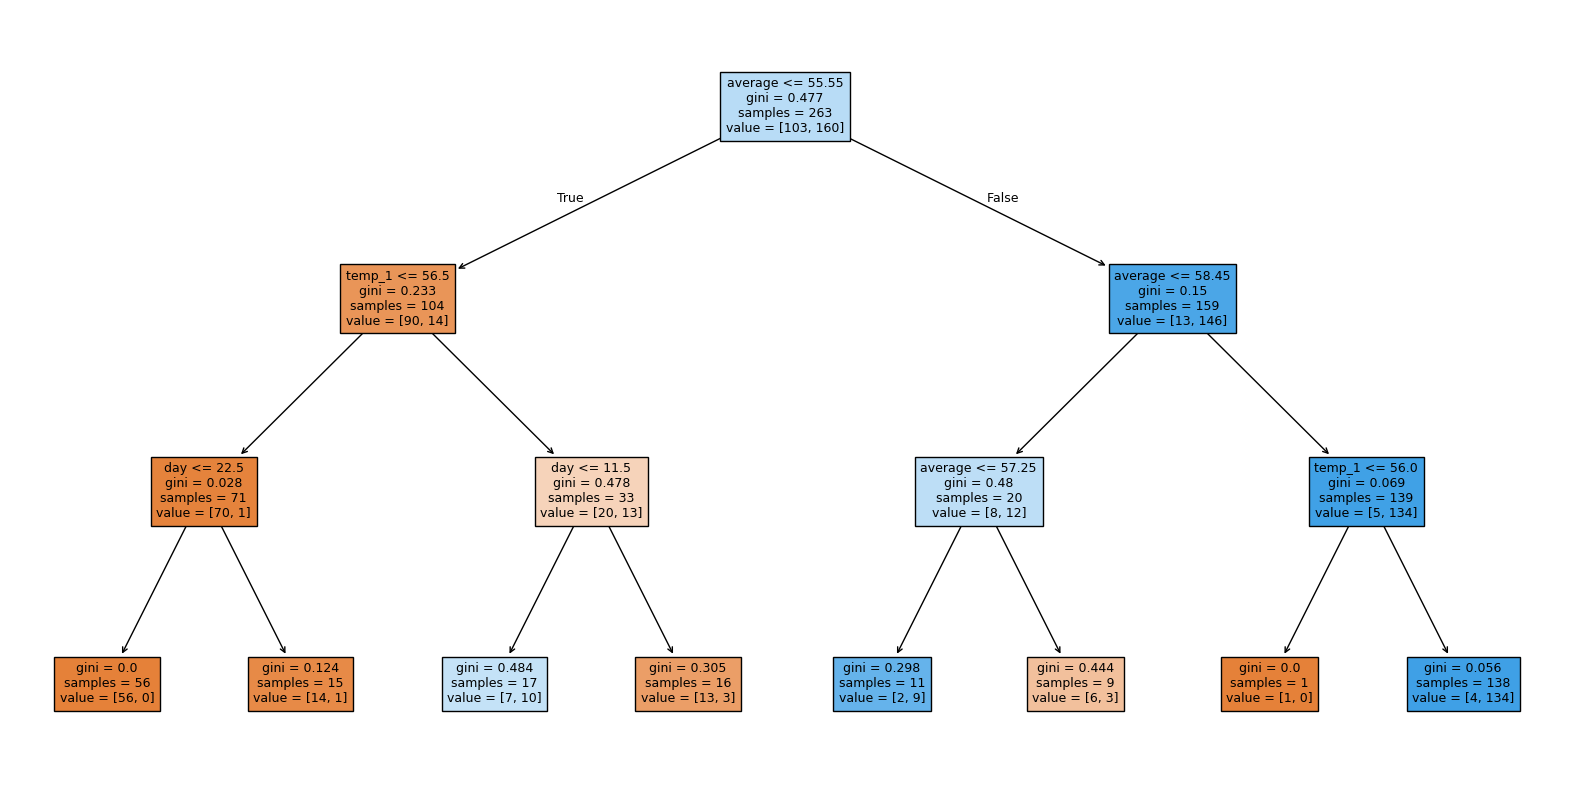

In [30]:
plt.figure(figsize=(20, 10))
plot_tree(tree_clf,
          feature_names=x_train.columns,
          max_depth=3,
          filled=True,
                #DIBUJAR ARBOL DE REGRESION
          fontsize=9)
plt.show()

In [31]:
y_clas_predict = tree_clf.predict(x_test)
x_clas_predict = tree_clf.predict(x_train)

In [35]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print('Acierto:', accuracy_score(y_test, y_clas_predict))
print(confusion_matrix(y_test, y_clas_predict))
print(classification_report(y_test, y_clas_predict))

print('---------------------------------------------------------------------------------')


print('Acierto:', accuracy_score(y_train, x_clas_predict))
print(confusion_matrix(y_train, x_clas_predict))
print(classification_report(y_train, x_clas_predict))


Acierto: 0.9545454545454546
[[22  0]
 [ 3 41]]
              precision    recall  f1-score   support

           0       0.88      1.00      0.94        22
           1       1.00      0.93      0.96        44

    accuracy                           0.95        66
   macro avg       0.94      0.97      0.95        66
weighted avg       0.96      0.95      0.96        66

---------------------------------------------------------------------------------
Acierto: 0.9239543726235742
[[ 90  13]
 [  7 153]]
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       103
           1       0.92      0.96      0.94       160

    accuracy                           0.92       263
   macro avg       0.92      0.92      0.92       263
weighted avg       0.92      0.92      0.92       263



In [33]:
parametros = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],     # None = sin límite
    'min_samples_leaf': [1, 5, 10, 20],            # mínimo de días que debe tener cada hoja
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=666),
    parametros,
    cv=5,                                    # validación cruzada de 5 partes
    scoring='neg_mean_absolute_error',       # elige el que menos se equivoca en grados
)
grid.fit(x_train, y_train)                

print('Mejores parámetros:', grid.best_params_)
print('MAE medio en la validación cruzada:', -grid.best_score_)

mejor_arbol = grid.best_estimator_           # ya viene entrenado con todo el train
y_pred_grid = mejor_arbol.predict(x_test)
print('MAE test:', metrics.mean_absolute_error(y_test, y_pred_grid))
print('R2 test: ', metrics.r2_score(y_test, y_pred_grid))

Mejores parámetros: {'max_depth': 2, 'min_samples_leaf': 10}
MAE medio en la validación cruzada: 0.1333091436865022
MAE test: 0.045454545454545456
R2 test:  0.7954545454545454
